# NAVTTC Week 6 - Task 53
## Decision Tree Classification

## Objective
Build and evaluate a **Decision Tree classifier**. A decision tree repeatedly splits the feature space using rules that reduce class impurity. Common split criteria include Gini impurity and entropy.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print(X.head())
print("\nClasses:", list(iris.target_names))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## Train/Test Split
A stratified split preserves approximately the same class proportions in the training and test sets.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## Evaluation

In [3]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.8947

Confusion Matrix:
[[12  0  0]
 [ 0 12  1]
 [ 0  3 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



## Visualize the Learned Tree

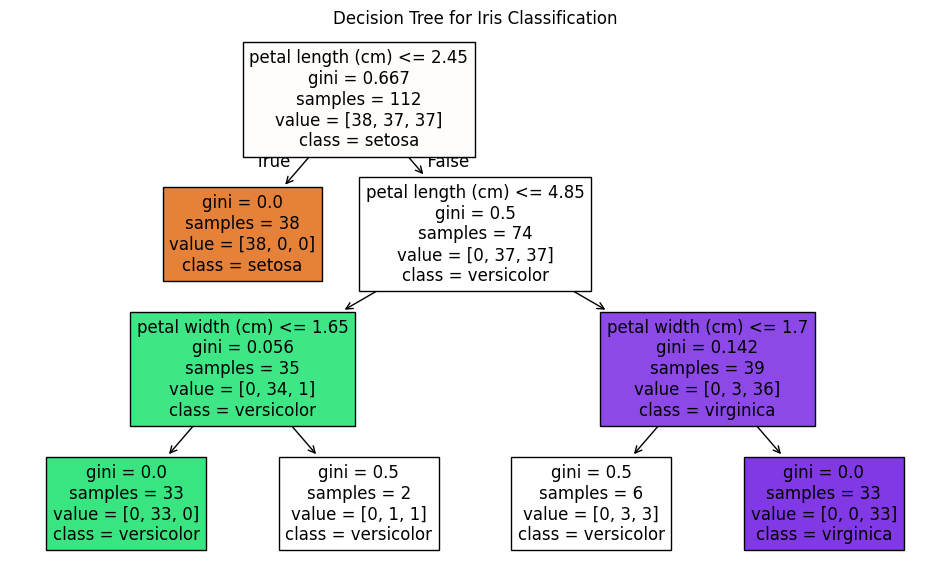

In [4]:
plt.figure(figsize=(12, 7))
plot_tree(model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.title("Decision Tree for Iris Classification")
plt.show()

## Feature Importance
Decision-tree feature importance summarizes how much each feature contributed to impurity reduction. It is a model-specific importance measure, not proof of causality.

In [5]:
importance = pd.Series(model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False))

petal length (cm)    0.950732
petal width (cm)     0.049268
sepal width (cm)     0.000000
sepal length (cm)    0.000000
dtype: float64


## Conclusion
This task demonstrates data preparation, tree training, prediction, evaluation, visualization, and feature-importance inspection.